# Paper solver timing comparison: which method is faster?

These executable figures reproduce the results in `paper/benchmarks/results/`. They **load recorded measurements**, rather than generating or fabricating benchmark times. The four methods are `dense_fresh`, `dense_cached`, `spectral` (SVD), and `banded` (SciPy's general `solve_banded`).

The scientific question is not just which algorithm has the cheapest one-off fit. We compare **total wall-clock time including preprocessing** for $M$ fits at the same penalty values, and separately compare $M$ trace/EDF evaluations. The underlying normal equations are equivalent:

$$\widehat\tau_\lambda = (I + \lambda D_d^\top D_d)^{-1}y, \qquad
\operatorname{EDF}(\lambda) = \operatorname{tr}[(I+\lambda D_d^\top D_d)^{-1}].$$

The full-fit timings are distinct from choosing $\lambda$ by CV/GCV/AICc/BIC, and **none of these four paper methods is labeled Cholesky**.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## 1. Load the existing measurements and machine provenance

The repository contains the raw CSV tables and hardware/software metadata. The figures below use those measurements exactly. If you run the paper benchmark suite again on your Windows 11 VM, rerun this notebook to render the **new local** data; don't merge measurements from different machines into an apparent single benchmark.

The four-way paper experiment here uses `scipy.linalg.solve_banded` for its structured solver; the separate 3-solver factorial and 20-seed Cholesky pilot have different methods and are not interchangeable.

In [2]:
import csv
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

repository = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "paper/benchmarks/results/full_fit_timings.csv").is_file()),
    None,
)
if repository is None:
    raise FileNotFoundError(
        "Run from the repository checkout containing paper/benchmarks/results/."
    )
data_dir = repository / "paper" / "benchmarks" / "results"
def read_table(filename):
    with (data_dir / filename).open(newline="", encoding="utf-8") as file:
        return list(csv.DictReader(file))

fits = read_table("full_fit_timings.csv")
traces = read_table("trace_timings.csv")
metadata = json.loads((data_dir / "environment.json").read_text(encoding="utf-8"))
print(f"{len(fits)} complete-fit rows; {len(traces)} EDF/trace rows")
for key in ("date_utc", "system", "processor", "python", "numpy",
            "scipy", "blas_threads", "preset", "repeats", "git_revision"):
    print(f"{key:>14}: {metadata.get(key, 'not recorded')}")


84 complete-fit rows; 20 EDF/trace rows
      date_utc: 2026-10-22T08:36:27.929289+00:00
        system: Windows-10-10.0.26100-SP0
     processor: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
        python: 3.11.17 | packaged by conda-forge | (main, Oct 13 2026, 16:36:10) [MSC v.1944 64 bit (AMD64)]
         numpy: 2.4.6
         scipy: 1.17.1
  blas_threads: 1
        preset: full
       repeats: 7
  git_revision: local-unrecorded


## 2. Full-curve fitted trends: how the workload changes the winner

For each pair $(n,M)$, compare total median time (preparation **plus** $M$ complete fitted curves), keeping $d=2$ and $\mu=0$ fixed. Log-scaled vertical axes make the differences legible. The x-axis is the number of candidate penalties, which could come from either a $\lambda$-grid or a mapped $S$-grid; **the four solver comparisons are conditional on the already supplied penalty values**, not the inversion cost of constructing them.

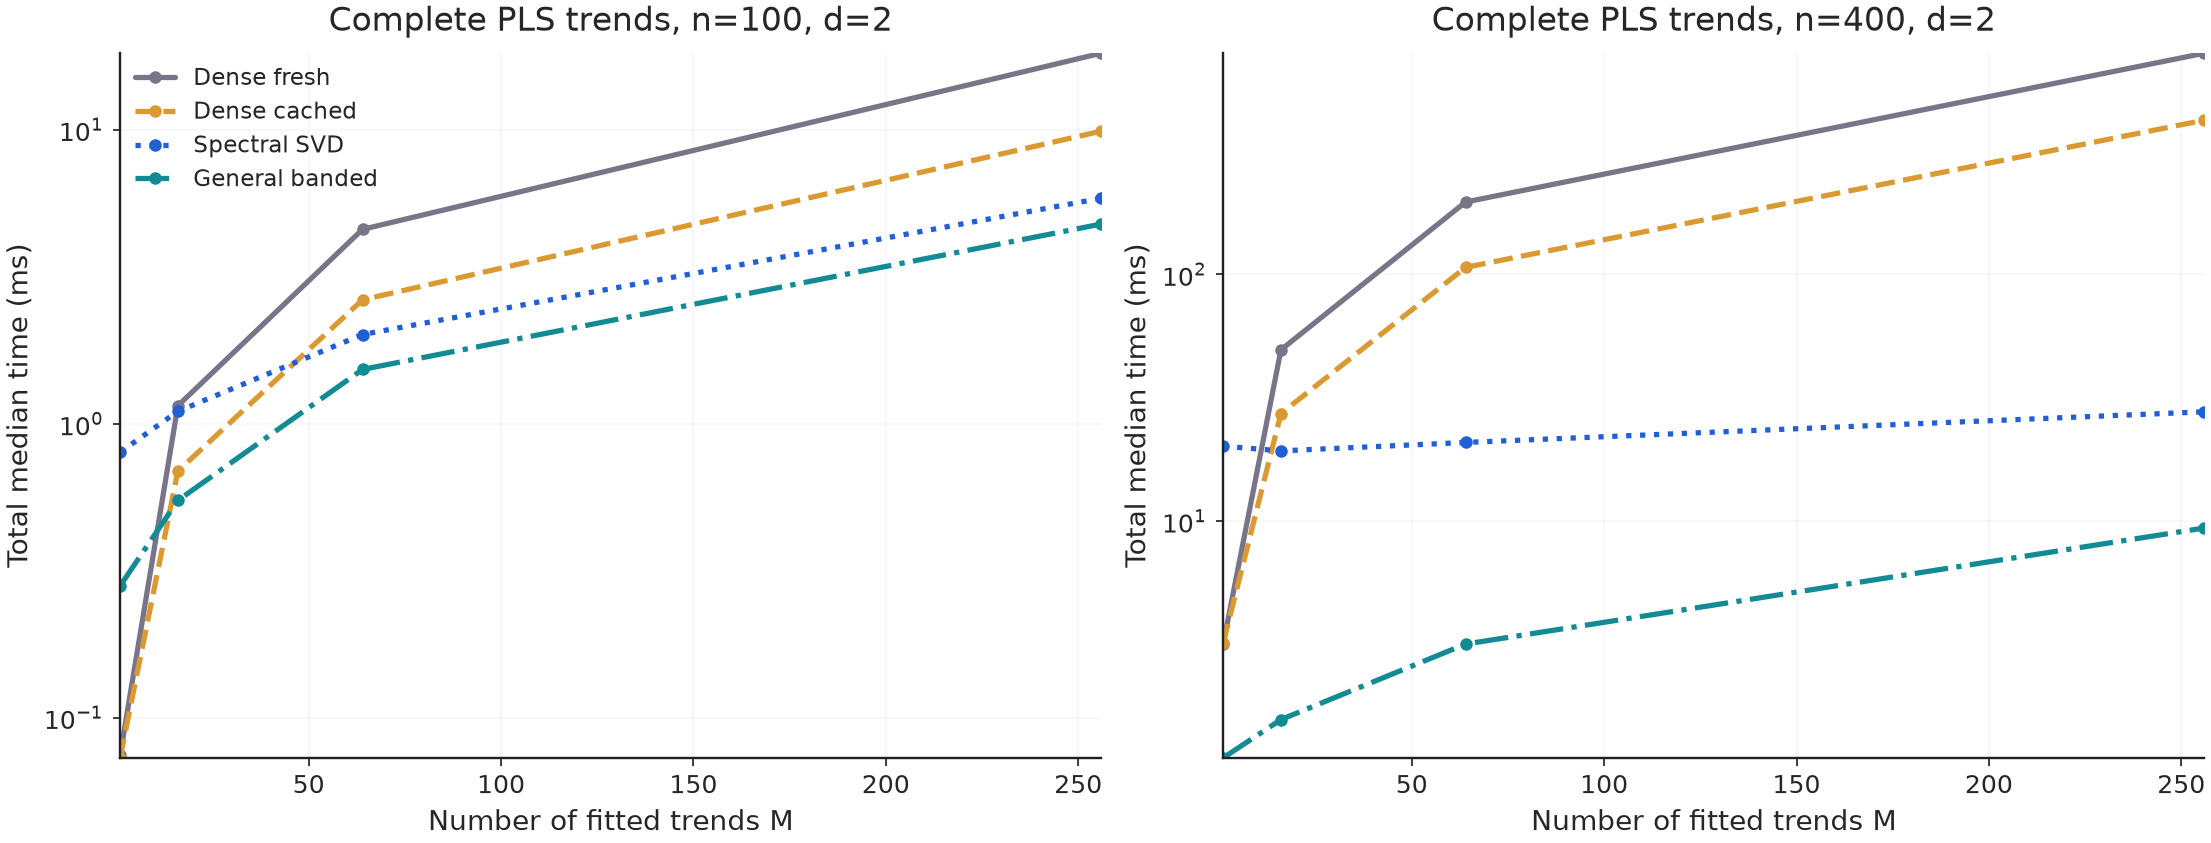

n=100, M=  1: dense_cached (0.073 ms) < dense_fresh (0.075 ms) < banded (0.281 ms) < spectral (0.801 ms)
n=100, M= 64: banded (1.532 ms) < spectral (2.013 ms) < dense_cached (2.642 ms) < dense_fresh (4.589 ms)
n=400, M= 64: banded (3.188 ms) < spectral (20.885 ms) < dense_cached (106.894 ms) < dense_fresh (196.554 ms)
n=400, M=256: banded (9.409 ms) < spectral (27.795 ms) < dense_cached (421.486 ms) < dense_fresh (787.002 ms)


In [3]:
methods = ("dense_fresh", "dense_cached", "spectral", "banded")
labels = ("Dense fresh", "Dense cached", "Spectral SVD", "General banded")
colors = ("#7a7489", "#db9a31", "#205fd4", "#138b94")

def select_fits(n, d=2, mu=0.0):
    return [row for row in fits if int(row["n"]) == n
            and int(row["d"]) == d and float(row["mu"]) == mu]

fig, axes = plt.subplots(1, 2, figsize=(12.3, 4.7), layout="constrained")
for ax, n in zip(axes, (100, 400)):
    rows = select_fits(n)
    for method, label, color in zip(methods, labels, colors):
        items = sorted((r for r in rows if r["method"] == method),
                       key=lambda r: int(r["M"]))
        ax.plot([int(r["M"]) for r in items],
                [1e3 * float(r["total_median_s"]) for r in items],
                marker="o", linewidth=2.1, markersize=4, color=color, label=label)
    ax.set(xlabel="Number of fitted trends M", ylabel="Total median time (ms)",
           title=f"Complete PLS trends, n={n}, d=2")
    ax.set_yscale("log")
    ax.grid(alpha=.22)
axes[0].legend(frameon=False, fontsize=9)
plt.show()

for n, m in ((100, 1), (100, 64), (400, 64), (400, 256)):
    matches = [r for r in select_fits(n) if int(r["M"]) == m]
    matches.sort(key=lambda r: float(r["total_median_s"]))
    print(f"n={n:3d}, M={m:3d}: " +
          " < ".join(f'{r["method"]} ({1e3*float(r["total_median_s"]):.3f} ms)'
                     for r in matches))


## 3. The best full-trend algorithm is not necessarily the best trace algorithm

Selecting smoothing by trace-based criteria benefits from repeated $\operatorname{tr}(H_\lambda)$ evaluations. After the SVD has been prepared, each trace can be evaluated from spectral attenuation factors in $O(n)$ work. The general banded baseline must compute each requested trace by its separate numerical procedure. Because the trace table varies both $n$ and $M$, each x-axis label explicitly shows the pair $(n,M)$.

These are **trace-only** profiles, not end-to-end optimization timings. In particular, CV additionally needs leverage values for all observations.

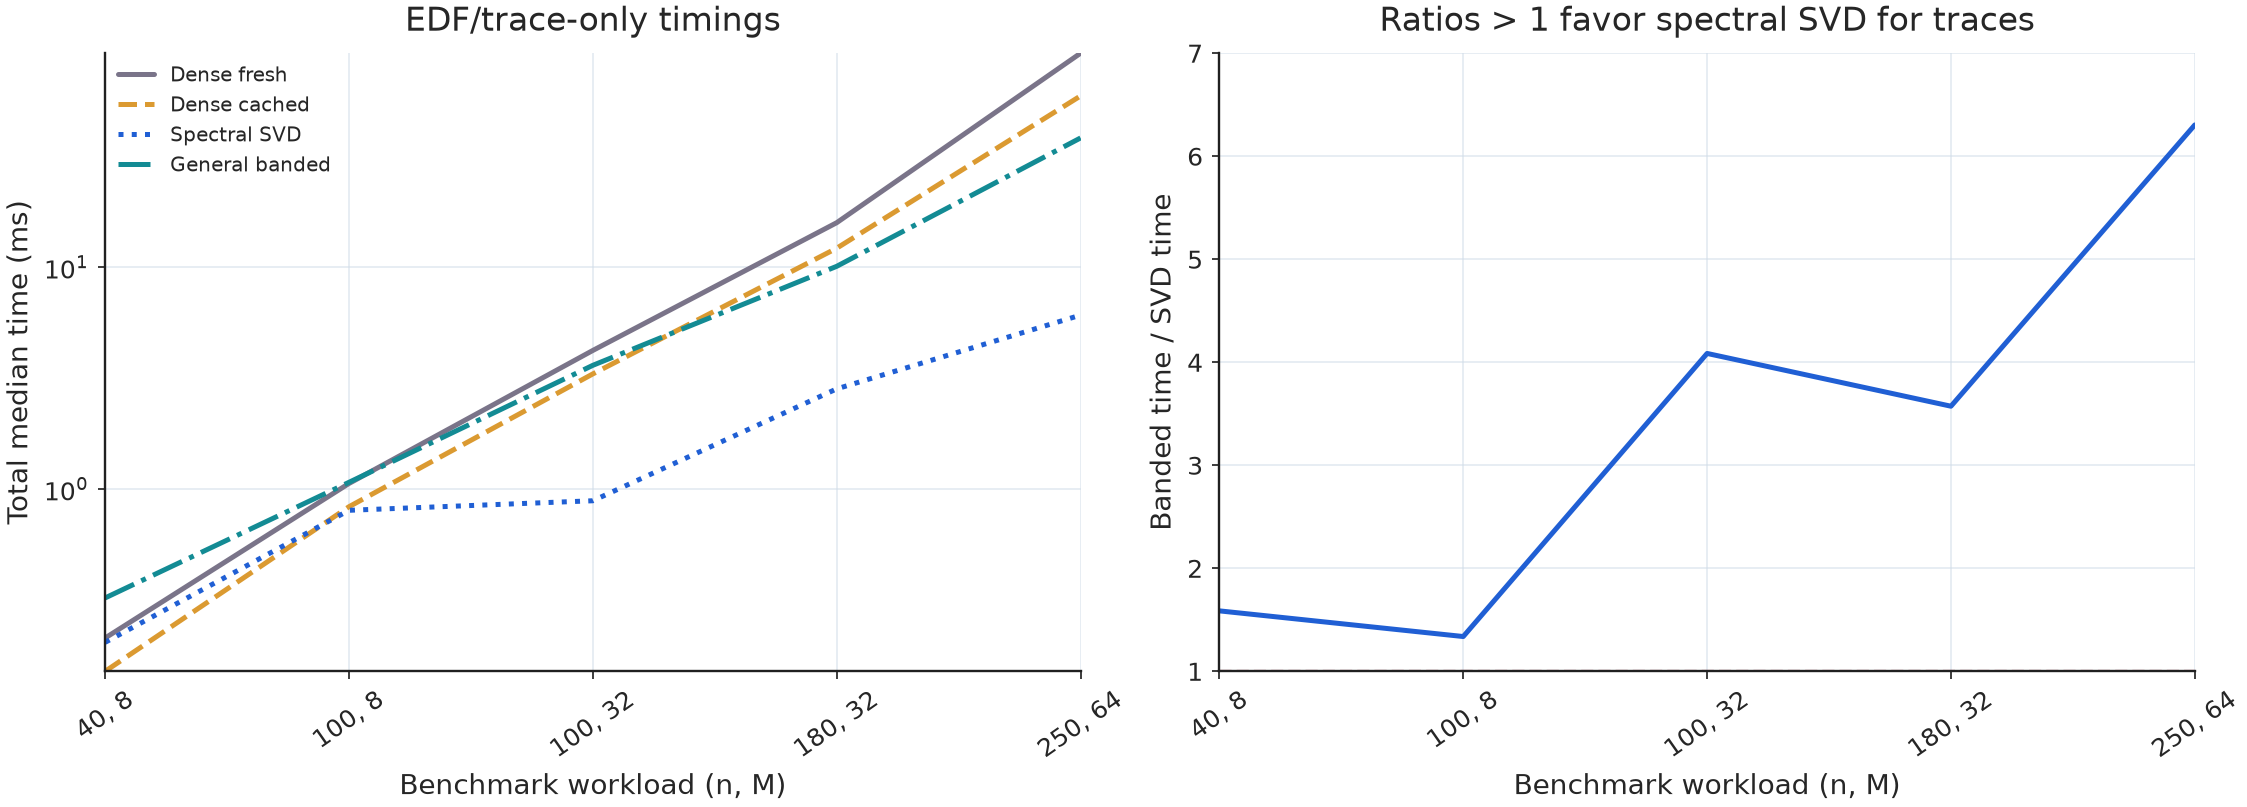

Largest trace workload: (250, 64) banded / spectral = 6.30x


In [4]:
ordered = sorted(set((int(r["n"]), int(r["M"])) for r in traces))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), layout="constrained")
for method, label, color in zip(
        ("dense_fresh_trace", "dense_cached_trace", "spectral_trace", "banded_trace"),
        labels, colors):
    ms = []
    for n, m in ordered:
        row = next(r for r in traces if int(r["n"]) == n
                   and int(r["M"]) == m and r["method"] == method)
        ms.append(1e3 * float(row["total_median_s"]))
    axes[0].plot(range(len(ordered)), ms, marker="o", linewidth=2,
                 color=color, label=label)
axes[0].set_yscale("log")
axes[0].set(xlabel="Benchmark workload (n, M)", ylabel="Total median time (ms)",
            title="EDF/trace-only timings")
axes[0].set_xticks(range(len(ordered)),
                   [f"{n}, {m}" for n, m in ordered], rotation=35)
axes[0].legend(frameon=False, fontsize=8)

speedups = []
for n, m in ordered:
    rows = [r for r in traces if int(r["n"]) == n and int(r["M"]) == m]
    times = {r["method"]:float(r["total_median_s"]) for r in rows}
    speedups.append(times["banded_trace"] / times["spectral_trace"])
axes[1].plot(range(len(ordered)), speedups, color="#205fd4",
             marker="o", linewidth=2)
axes[1].axhline(1, color="#bf5268", linestyle="--", linewidth=1.3)
axes[1].set(xlabel="Benchmark workload (n, M)", ylabel="Banded time / SVD time",
            title="Ratios > 1 favor spectral SVD for traces")
axes[1].set_xticks(range(len(ordered)),
                   [f"{n}, {m}" for n, m in ordered], rotation=35)
plt.show()

print("Largest trace workload:", ordered[-1],
      f"banded / spectral = {speedups[-1]:.2f}x")


## 4. Numerical agreement and method selection

The measured routines should return the **same trends** up to numerical tolerance; selecting the fastest implementation must not sacrifice numerical correctness. The CSV contains `max_error_banded` for every complete-fit case and `max_abs_trace_error` for every trace case.

- **One or a few full fits:** cached dense methods may outperform methods requiring an up-front SVD.
- **Many full fits:** the properly structured general banded solver dominates many of the larger tested $(n,M,d)$ workloads.
- **Many trace values:** the spectral representation can amortize its decomposition and is decisively faster in the larger recorded trace workloads.
- **High difference order:** the effective bandwidth, conditioning, and implementation matter; do not claim a universal algorithm from one machine.

A separate project study in `paper/benchmarks/solver_study_runs/pilot-01/analysis/results.md` tests **SVD vs symmetric eigendecomposition vs actual banded Cholesky** using seed-level repeated timings and multiplicity adjustment. That is a different experiment from this notebook's four-way paper table.

Maximum fit discrepancy vs general banded: 4.321e-10
Maximum EDF/trace discrepancy: 5.478e-12


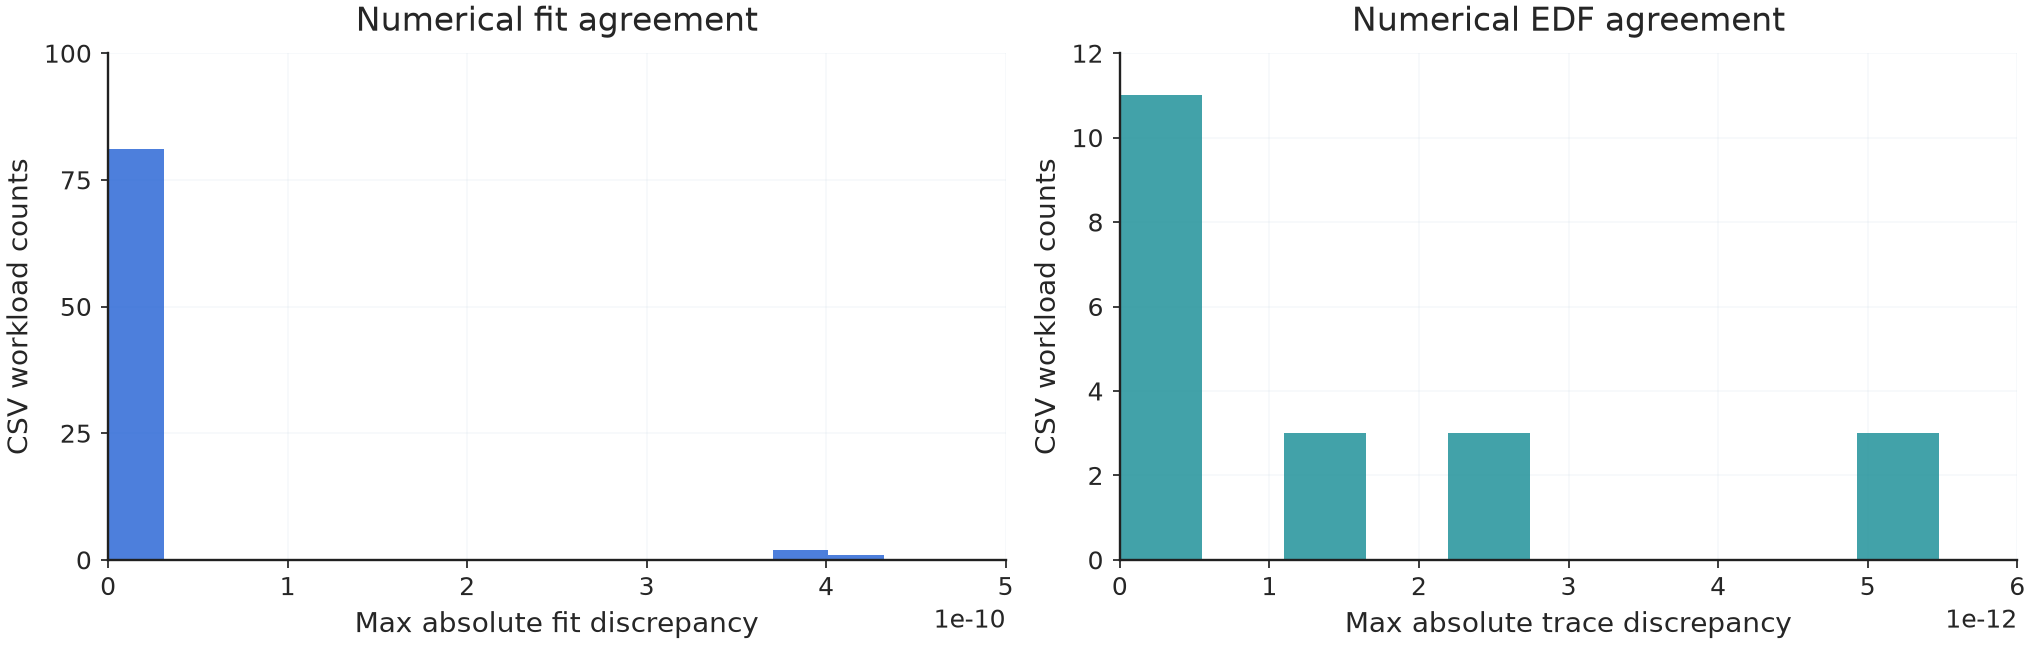

In [5]:
max_trend_error = max(float(r["max_error_banded"]) for r in fits)
max_trace_error = max(float(r["max_abs_trace_error"]) for r in traces)
print(f"Maximum fit discrepancy vs general banded: {max_trend_error:.3e}")
print(f"Maximum EDF/trace discrepancy: {max_trace_error:.3e}")
assert max_trend_error < 3e-6, "Trend methods lost numerical parity"
assert max_trace_error < 1e-6, "Trace methods lost numerical parity"

fig, axes = plt.subplots(1, 2, figsize=(11.3, 3.6), layout="constrained")
axes[0].hist([float(r["max_error_banded"]) for r in fits],
             bins=14, color="#205fd4", alpha=.8)
axes[0].set(xlabel="Max absolute fit discrepancy", ylabel="CSV workload counts",
            title="Numerical fit agreement")
axes[1].hist([float(r["max_abs_trace_error"]) for r in traces],
             bins=10, color="#138b94", alpha=.8)
axes[1].set(xlabel="Max absolute trace discrepancy", ylabel="CSV workload counts",
            title="Numerical EDF agreement")
for ax in axes:
    ax.grid(alpha=.2)
plt.show()


## 5. Reproduce and interpret the numbers

From Windows 11 PowerShell at the repository root:

```powershell
conda activate trendestimation
python paper\benchmarks\run_all.py --preset full --repeats 7
python scripts\run_notebooks.py --only 11-paper-solver-timing-comparison --in-place --fail-fast
```

The first command **overwrites local result CSV files** with current VM measurements, and the second re-embeds the figures. The committed example uses the versioned CSV data from this repository. Rerunning on a different machine does not reproduce identical clock times.

The practical optimization idea is to **choose a meaningful candidate grid in $S$**, invert it once to obtain $\lambda$ values (including exact $0$ and $+\infty$), and then reuse that mapped penalty grid for all criteria. This is a candidate-selection strategy; it does not replace the independent linear-algebra benchmark. A sparse uniform 11-point grid by itself can miss a sharp optimum near 1, so also examine the enriched tail $(0.95,0.99,0.999,0.9999,0.999999)$.